# Who Has a Bank Account? Predicting Financial Inclusion Across Countries

This notebook follows the CRISP-DM process:

1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Deployment (the findings are shared in a blog post and in the README)

## 1. Business Understanding

A bank or mobile money account is the entry point to saving, borrowing and getting paid. The World Bank measures it through the Global Findex survey as the share of adults (age 15 and above) who own an account.

A development agency, a bank or a fintech company deciding where to work would want to know where account ownership is low, what goes with it, and how far it can be predicted from data that is published every year.

**Questions**

1. How has account ownership changed between 2011 and 2024, and how do world regions differ?
2. Which country characteristics are most strongly related to account ownership?
3. How accurately can a model predict account ownership, and which features does it rely on most?
4. Which countries have many more, or many fewer, account owners than their income level predicts?
5. What does the model predict for a typical lower middle income country if internet use rises?

## 2. Data Understanding

### 2.1 Gather

All data come from the World Bank Databank through its public API. The target is the Findex account ownership indicator. The twelve features are country indicators that are published every year.

In [1]:
import json
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

%matplotlib inline
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [2]:
API_URL = 'https://api.worldbank.org/v2'
DATA_DIR = 'data'
RAW_INDICATORS_FILE = os.path.join(DATA_DIR, 'raw_worldbank_indicators.csv')
RAW_COUNTRIES_FILE = os.path.join(DATA_DIR, 'raw_worldbank_countries.csv')
CLEAN_FILE = os.path.join(DATA_DIR, 'clean_account_ownership.csv')
START_YEAR, END_YEAR = 2010, 2024

TARGET = 'account_ownership'
INDICATORS = {
    'FX.OWN.TOTL.ZS': TARGET,
    'NY.GDP.PCAP.CD': 'gdp_per_capita',
    'IT.NET.USER.ZS': 'internet_users',
    'IT.CEL.SETS.P2': 'mobile_subscriptions',
    'SP.URB.TOTL.IN.ZS': 'urban_population',
    'FB.CBK.BRCH.P5': 'bank_branches',
    'FB.ATM.TOTL.P5': 'atms',
    'SE.SEC.ENRR': 'secondary_enrollment',
    'SL.TLF.CACT.ZS': 'labor_participation',
    'SP.POP.65UP.TO.ZS': 'population_65_plus',
    'SL.UEM.TOTL.ZS': 'unemployment',
    'FP.CPI.TOTL.ZG': 'inflation',
    'EG.ELC.ACCS.ZS': 'electricity_access',
}

In [3]:
def fetch_json(url):
    """Download one World Bank API page and return the parsed JSON.

    Args:
        url (str): Full API address, including the query string.

    Returns:
        list: The API response, a two item list of metadata and records.
    """
    headers = {'User-Agent': 'Mozilla/5.0'}
    request = urllib.request.Request(url, headers=headers)
    with urllib.request.urlopen(request, timeout=120) as response:
        return json.loads(response.read())


def fetch_indicator(code, name):
    """Download one indicator for every country and year in the study window.

    Args:
        code (str): World Bank indicator code, for example 'NY.GDP.PCAP.CD'.
        name (str): Column name to give the indicator.

    Returns:
        pandas.DataFrame: Columns country_code, year and the indicator.
    """
    url = (f'{API_URL}/country/all/indicator/{code}?format=json'
           f'&per_page=20000&date={START_YEAR}:{END_YEAR}')
    records = fetch_json(url)[1]
    rows = [(r['countryiso3code'], int(r['date']), r['value'])
            for r in records]
    return pd.DataFrame(rows, columns=['country_code', 'year', name])


def gather_indicators(indicators, path):
    """Return all indicators in one table, reusing a saved raw file.

    Args:
        indicators (dict): Maps indicator codes to column names.
        path (str): Where the raw table is saved.

    Returns:
        pandas.DataFrame: One row per country and year.
    """
    if os.path.exists(path):
        return pd.read_csv(path)
    tables = [fetch_indicator(code, name).set_index(['country_code', 'year'])
              for code, name in indicators.items()]
    raw = pd.concat(tables, axis=1).reset_index()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    raw.to_csv(path, index=False)
    return raw


def gather_countries(path):
    """Return the World Bank country list, reusing a saved raw file.

    Args:
        path (str): Where the raw table is saved.

    Returns:
        pandas.DataFrame: Columns country_code, country, region, income_group.
    """
    if os.path.exists(path):
        return pd.read_csv(path)
    records = fetch_json(f'{API_URL}/country?format=json&per_page=400')[1]
    rows = [(r['id'], r['name'], r['region']['value'].strip(),
             r['incomeLevel']['value']) for r in records]
    countries = pd.DataFrame(
        rows, columns=['country_code', 'country', 'region', 'income_group'])
    os.makedirs(os.path.dirname(path), exist_ok=True)
    countries.to_csv(path, index=False)
    return countries

In [4]:
raw = gather_indicators(INDICATORS, RAW_INDICATORS_FILE)
countries = gather_countries(RAW_COUNTRIES_FILE)
print('Indicator table:', raw.shape)
print('Country table:', countries.shape)
raw.head()

Indicator table: (3990, 15)
Country table: (296, 4)


,country_code,year,account_ownership,gdp_per_capita,internet_users,mobile_subscriptions,urban_population,bank_branches,atms,secondary_enrollment,labor_participation,population_65_plus,unemployment,inflation,electricity_access
0,AFE,2024,NaN,1628.227289,28.8,87.3,38.241441,4.519533,7.286298,45.606079,68.876587,3.330960,7.571697,4.770857,52.598171
1,AFE,2023,NaN,1571.132704,27.8,82.3,37.772301,4.477681,8.145050,45.155392,68.884368,3.286303,7.676548,7.399186,50.667516
2,AFE,2022,NaN,1675.902524,26.8,77.7,37.360578,3.738280,7.991180,45.281620,66.397433,3.246111,7.869470,10.883478,48.742043
3,AFE,2021,NaN,1560.894626,25.0,74.7,36.908543,3.806199,7.714876,45.150532,66.033662,3.216573,8.407412,6.824727,48.127211
4,AFE,2020,NaN,1351.503167,23.5,69.9,36.488322,4.079277,8.581639,44.682560,65.953109,3.192169,7.974302,5.191629,46.282371


### 2.2 Assess

Three things need checking before any analysis: which rows are real countries, how much of each column is missing, and how the variables are distributed.

In [5]:
print(countries['region'].value_counts())

region
Aggregates                                           79
Europe & Central Asia                                58
Sub-Saharan Africa                                   48
Latin America & Caribbean                            42
East Asia & Pacific                                  37
Middle East, North Africa, Afghanistan & Pakistan    23
South Asia                                            6
North America                                         3
Name: count, dtype: int64


In [6]:
has_target = raw[TARGET].notna()
print('Rows with an account ownership value:', has_target.sum(),
      'of', len(raw))
print(raw.loc[has_target, 'year'].value_counts().sort_index())

Rows with an account ownership value: 804 of 3990
year
2011    165
2014    162
2017    166
2021    144
2022     16
2024    151
Name: count, dtype: int64


In [7]:
indicator_columns = raw.loc[has_target].drop(columns=['country_code', 'year'])
missing_share = indicator_columns.isna().mean().sort_values(ascending=False)
print((missing_share * 100).round(1))

secondary_enrollment    24.4
atms                     6.8
bank_branches            5.5
internet_users           4.5
mobile_subscriptions     4.1
inflation                2.2
labor_participation      1.0
unemployment             1.0
electricity_access       0.6
gdp_per_capita           0.4
account_ownership        0.0
urban_population         0.0
population_65_plus       0.0
dtype: float64


In [8]:
indicator_columns.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
account_ownership,804.0,60.03,28.42,0.40,37.19,59.74,87.13,100.00
gdp_per_capita,801.0,15774.37,21092.08,230.07,2179.88,6434.65,20285.23,123678.71
internet_users,768.0,54.83,30.06,0.90,28.29,59.45,81.61,100.00
mobile_subscriptions,771.0,109.23,36.17,19.70,88.06,110.49,128.73,364.85
urban_population,804.0,60.81,21.01,11.56,44.18,62.35,78.39,100.00
bank_branches,760.0,16.15,13.93,0.51,5.98,12.39,22.15,93.84
atms,749.0,48.85,46.29,0.38,12.26,39.98,64.85,306.46
secondary_enrollment,608.0,86.38,26.66,13.66,72.33,92.51,103.18,162.42
labor_participation,796.0,60.78,9.62,33.02,55.63,61.12,66.05,86.46
population_65_plus,804.0,9.38,6.50,0.93,3.61,7.02,14.86,29.78


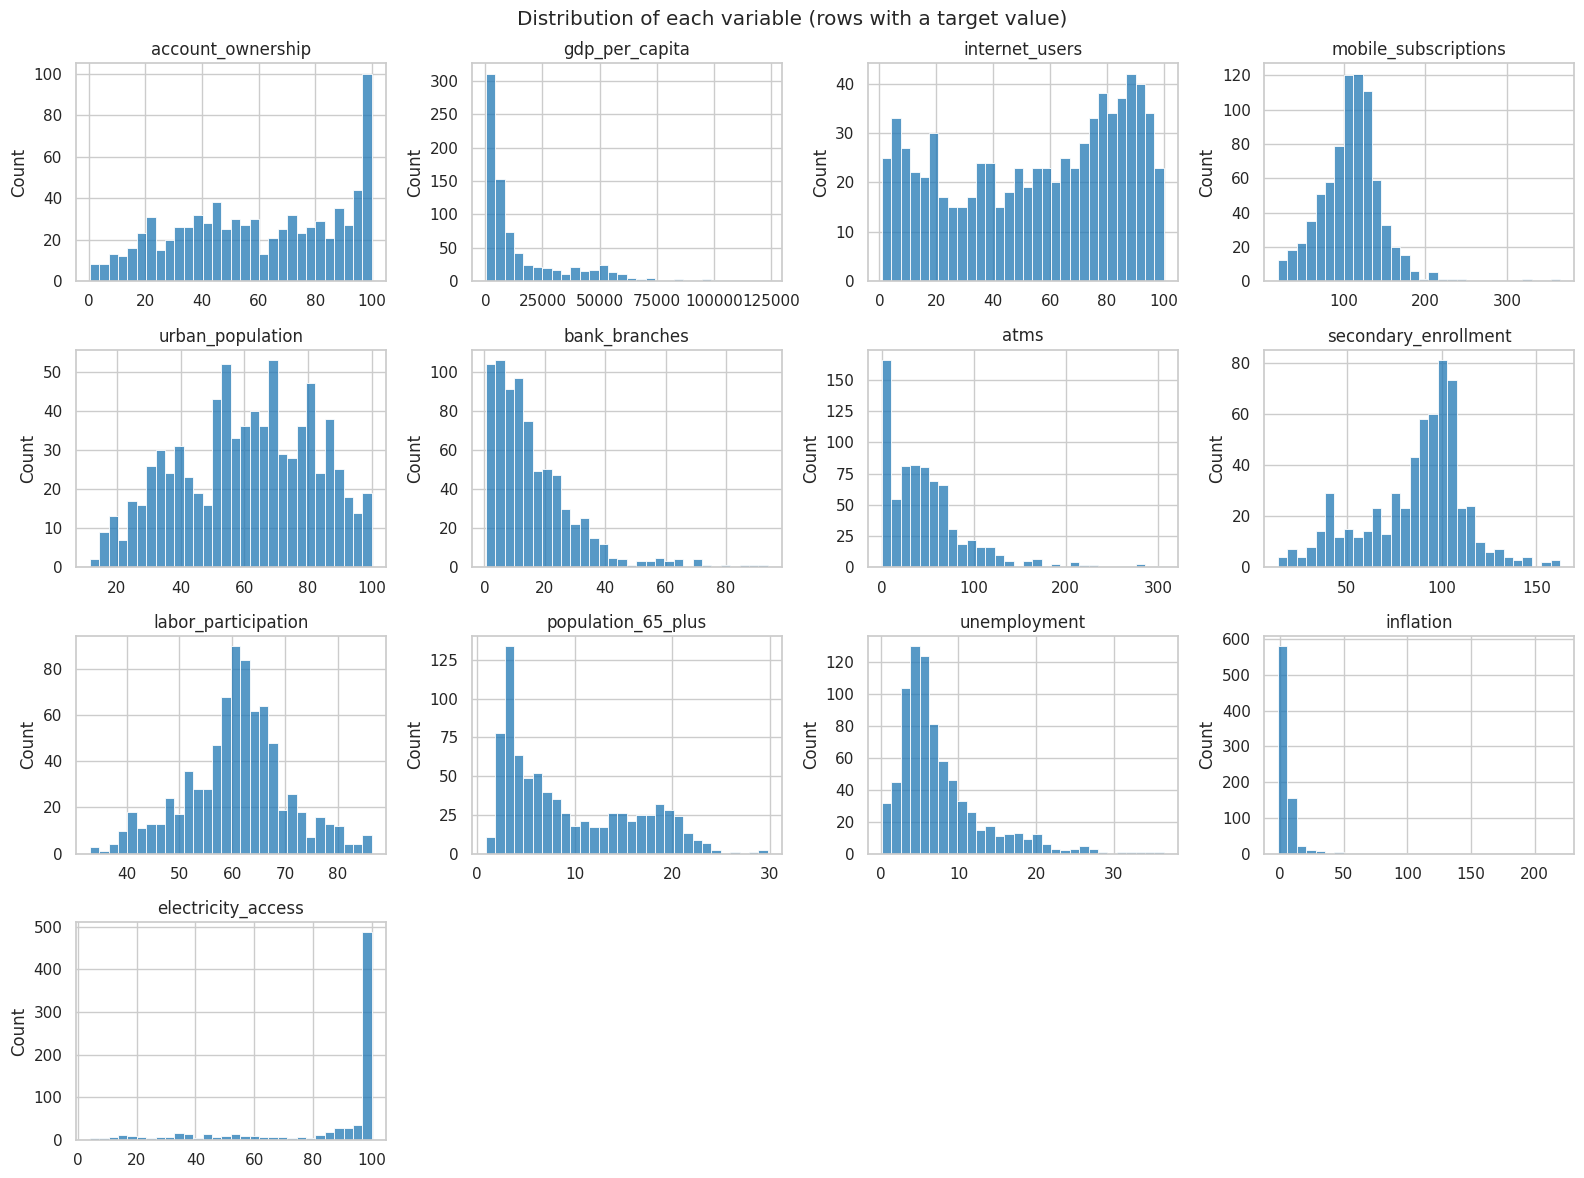

In [9]:
def plot_histograms(data, columns, ncols=4):
    """Draw one histogram per column to show how each variable is distributed.

    Args:
        data (pandas.DataFrame): Table that holds the columns.
        columns (list): Names of the numeric columns to plot.
        ncols (int): Number of charts per row.
    """
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    for axis, column in zip(axes.ravel(), columns):
        sns.histplot(data[column].dropna(), bins=30, ax=axis, color='#1f77b4')
        axis.set_title(column)
        axis.set_xlabel('')
    for axis in axes.ravel()[len(columns):]:
        axis.set_visible(False)
    fig.suptitle('Distribution of each variable (rows with a target value)')
    fig.tight_layout()
    plt.show()


plot_histograms(raw.loc[has_target], list(INDICATORS.values()))

**What the assessment shows**

* The indicator table has 3,990 rows, but only 804 have an account ownership value. The Findex survey runs about every three years (2011, 2014, 2017, 2021 and 2024), with 16 countries surveyed in 2022 instead of 2021.
* The country list has 296 entries, and 79 of them are aggregates such as "World" or income groups. These are not countries and must be removed.
* Secondary school enrollment is missing in 24.4% of the rows that have a target. ATMs (6.8%), bank branches (5.5%), internet users (4.5%) and mobile subscriptions (4.1%) have smaller gaps. The other features are almost complete.
* GDP per capita, bank branches, ATMs and inflation are strongly skewed to the right. Account ownership itself covers the full range from close to 0% to 100%.

## 3. Data Preparation

### 3.1 Clean

In [10]:
def clean_data(raw_table, country_table):
    """Keep real countries with a target value and add the country attributes.

    Steps:
        1. Drop rows with no account ownership value (nothing to learn from).
        2. Drop World Bank aggregates such as "World" or "Euro area".
        3. Add country name, region and income group.
        4. Add the base 10 logarithm of GDP per capita.

    Args:
        raw_table (pandas.DataFrame): Output of gather_indicators.
        country_table (pandas.DataFrame): Output of gather_countries.

    Returns:
        pandas.DataFrame: The cleaned analysis table.
    """
    real = country_table[country_table['region'] != 'Aggregates']
    clean = raw_table.dropna(subset=[TARGET]).merge(
        real, on='country_code', how='inner', validate='many_to_one')
    clean['log_gdp_per_capita'] = np.log10(clean['gdp_per_capita'])
    return clean.sort_values(['country', 'year']).reset_index(drop=True)


df = clean_data(raw, countries)
df.to_csv(CLEAN_FILE, index=False)
print('Rows:', len(df), '| Countries:', df['country_code'].nunique())
print(df['year'].value_counts().sort_index())
df.head()

Rows: 705 | Countries: 161
year
2011    143
2014    141
2017    144
2021    122
2022     16
2024    139
Name: count, dtype: int64


,country_code,year,account_ownership,gdp_per_capita,internet_users,mobile_subscriptions,urban_population,bank_branches,atms,secondary_enrollment,labor_participation,population_65_plus,unemployment,inflation,electricity_access,country,region,income_group,log_gdp_per_capita
0,AFG,2011,9.005012,606.694676,5.000000,47.015184,22.820569,2.395722,0.665860,52.447430,46.884,2.322140,7.830,11.804186,43.2,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2.782970
1,AFG,2014,9.961001,625.054942,7.000000,56.132210,24.191017,2.502790,0.814305,54.293652,47.096,2.356536,7.915,4.673996,89.5,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2.795918
2,AFG,2017,14.893312,525.469771,13.500000,67.050790,24.835282,2.229771,1.329286,55.536430,47.305,2.359737,11.184,4.975952,97.7,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2.720548
3,AFG,2021,9.653822,356.496214,16.514299,56.694476,25.347862,NaN,NaN,NaN,40.684,2.352550,12.006,5.133203,97.7,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2.552055
4,ALB,2011,28.268124,4465.709143,47.000000,106.474180,53.291738,23.941753,35.042020,95.470528,59.938,11.228183,13.481,3.428071,99.7,Albania,Europe & Central Asia,Upper middle income,3.649890


### 3.2 Missing values and categorical variables

**Missing target.** Rows without an account ownership value were dropped, because a model cannot learn from an unknown answer and filling in the answer would invent data.

**Missing features.** For the descriptive questions (1, 2 and 4) each statistic simply uses the rows that have the value, so nothing is filled in. For the model, the gaps are filled with the median of the training data, inside the pipeline. The median is used because several features are strongly skewed, and filling inside the pipeline means the test countries never influence the fill value. Dropping incomplete rows instead would remove about a third of the data (only 66% of rows have every feature).

**Categorical variable.** Region is a category with no natural order, so it is one-hot encoded. Income group is left out of the model on purpose: the World Bank defines it from income per person, which GDP per capita already measures.

**Skew.** GDP per capita spans three orders of magnitude, so its logarithm is used.

In [11]:
NUMERIC_FEATURES = ['log_gdp_per_capita', 'internet_users',
                    'mobile_subscriptions', 'urban_population',
                    'bank_branches', 'atms', 'secondary_enrollment',
                    'labor_participation', 'population_65_plus',
                    'unemployment', 'inflation', 'electricity_access', 'year']
CATEGORICAL_FEATURES = ['region']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

complete_rows = df[FEATURES].notna().all(axis=1).mean()
print(f'Rows with every feature present: {complete_rows:.0%}')

Rows with every feature present: 66%


## 4. Analysis

### Question 1. How has account ownership changed, and how do regions differ?

In [12]:
SURVEY_YEARS = [2011, 2014, 2017, 2021, 2024]
survey = df[df['year'].isin(SURVEY_YEARS)]
print(survey.groupby('year')[TARGET].agg(['count', 'median']).round(1))

region_trend = survey.pivot_table(
    index='year', columns='region', values=TARGET, aggfunc='median').round(1)
region_trend

      count  median
year               
2011    143    37.0
2014    141    52.0
2017    144    58.6
2021    122    73.7
2024    139    72.8


region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
year,,,,,,,
2011,72.7,73.2,28.0,35.2,91.9,33.5,17.3
2014,80.7,82.2,45.6,46.9,96.3,33.8,22.3
2017,83.5,83.5,48.7,44.8,96.4,73.6,40.5
2021,95.6,94.2,64.2,44.1,97.3,65.8,50.8
2024,91.8,90.0,64.3,44.4,97.7,70.8,55.6


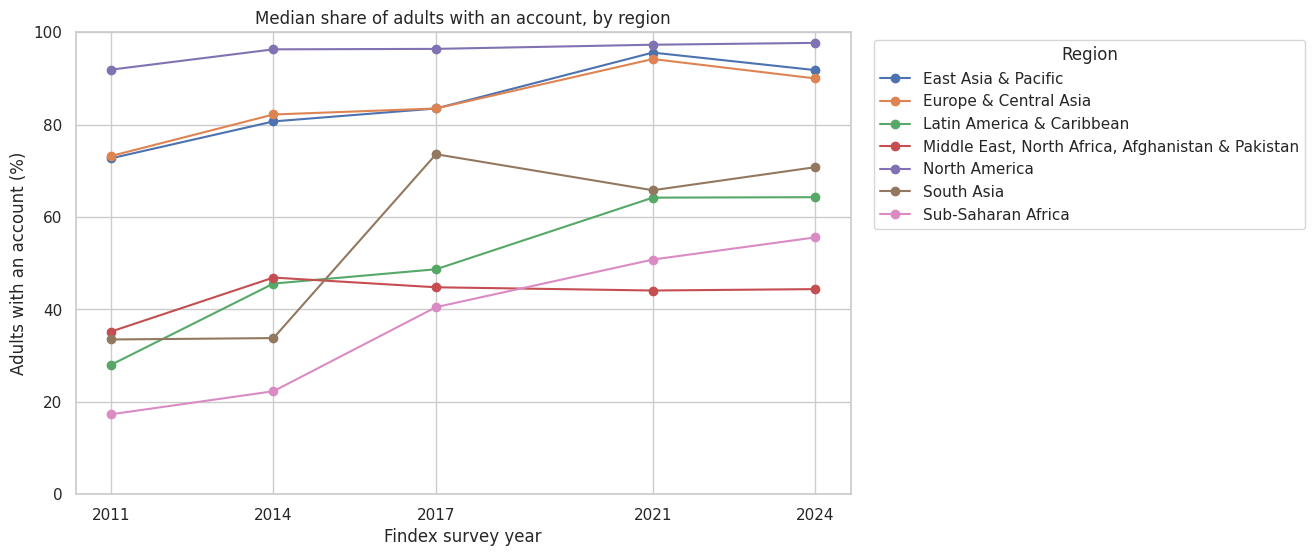

In [13]:
ax = region_trend.plot(marker='o', figsize=(10, 6))
ax.set_title('Median share of adults with an account, by region')
ax.set_xlabel('Findex survey year')
ax.set_ylabel('Adults with an account (%)')
ax.set_xticks(SURVEY_YEARS)
ax.set_ylim(0, 100)
ax.legend(title='Region', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

**Answer.** Account ownership has roughly doubled. The median country had 37.0% of adults with an account in 2011 (143 countries) and 72.8% in 2024 (139 countries).

The gain was largest where the starting point was lowest. Sub-Saharan Africa went from a median of 17.3% to 55.6%, South Asia from 33.5% to 70.8%, and Latin America and the Caribbean from 28.0% to 64.3%. The Middle East, North Africa, Afghanistan and Pakistan region is the exception: its median was 46.9% in 2014 and 44.4% in 2024. North America, Europe and Central Asia, and East Asia and Pacific were already high and are now at or above 90%.

*Limits.* These are medians of countries, so a small country counts as much as a large one. The set of countries surveyed is not identical every year (122 countries in 2021 against 139 in 2024), so small moves between two years, such as the dip in some regions after 2021, should not be read as real declines.

### Question 2. Which country characteristics are most strongly related to account ownership?

Spearman rank correlation is used because several relationships are curved rather than straight.

inflation              -0.39
labor_participation     0.01
unemployment            0.08
year                    0.28
mobile_subscriptions    0.52
bank_branches           0.54
urban_population        0.57
electricity_access      0.71
atms                    0.71
population_65_plus      0.72
secondary_enrollment    0.75
internet_users          0.80
log_gdp_per_capita      0.81
Name: account_ownership, dtype: float64


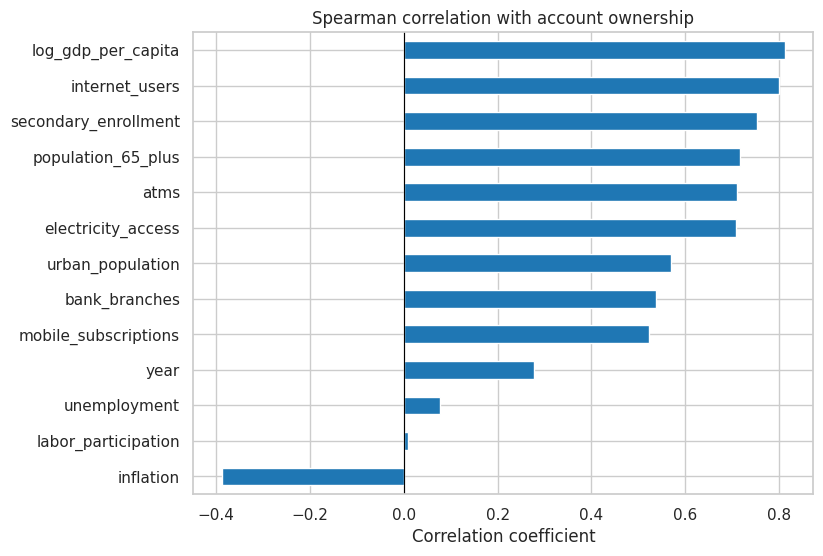

In [14]:
correlations = df[NUMERIC_FEATURES + [TARGET]].corr(method='spearman')[TARGET]
correlations = correlations.drop(TARGET).sort_values()
print(correlations.round(2))

ax = correlations.plot(kind='barh', figsize=(8, 6), color='#1f77b4')
ax.set_title('Spearman correlation with account ownership')
ax.set_xlabel('Correlation coefficient')
ax.axvline(0, color='black', linewidth=0.8)
plt.show()

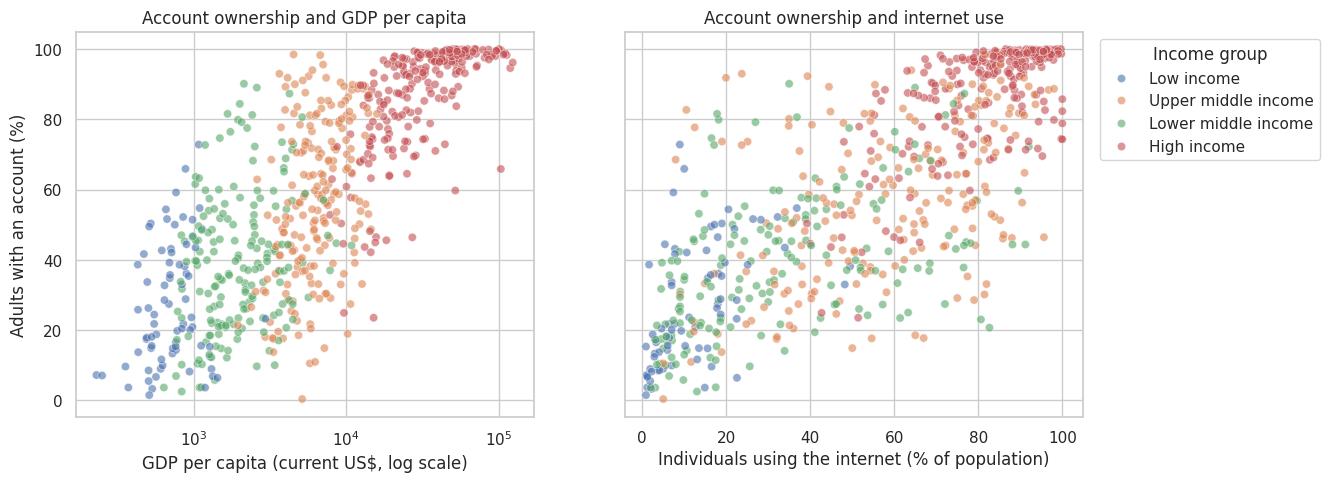

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
sns.scatterplot(data=df, x='gdp_per_capita', y=TARGET, hue='income_group',
                alpha=0.6, ax=axes[0], legend=False)
axes[0].set_xscale('log')
axes[0].set_title('Account ownership and GDP per capita')
axes[0].set_xlabel('GDP per capita (current US$, log scale)')
axes[0].set_ylabel('Adults with an account (%)')
sns.scatterplot(data=df, x='internet_users', y=TARGET, hue='income_group',
                alpha=0.6, ax=axes[1])
axes[1].set_title('Account ownership and internet use')
axes[1].set_xlabel('Individuals using the internet (% of population)')
axes[1].legend(title='Income group', bbox_to_anchor=(1.02, 1),
               loc='upper left')
plt.show()

**Answer.** Income and connectivity have the strongest relationship with account ownership. The Spearman correlation is 0.81 for GDP per capita and 0.80 for internet use. Secondary school enrollment (0.75), the share of people aged 65 and above (0.72), ATMs per 100,000 adults (0.71) and access to electricity (0.71) follow.

Two results are less expected. Mobile phone subscriptions (0.52) and bank branches (0.54) are only moderately related, even though both are direct routes to an account. Unemployment (0.08) and labor force participation (0.01) show almost no relationship. Inflation is the only clearly negative one (-0.39): countries with higher inflation tend to have fewer account owners.

*Limits.* These are associations between country averages, not causes. The strongest features are also strongly related to each other, since richer countries have more internet, more schooling and older populations.

### Question 3. How accurately can a model predict account ownership, and which features does it rely on?

**Design choices**

* The target is a percentage, so this is a regression problem. Accuracy and recall belong to classification; the matching measures here are R squared, mean absolute error (MAE) and root mean squared error (RMSE).
* Each country appears up to six times. If the same country were in both the training and the test data, the model could look good just by remembering countries. The split is therefore made by country: every row of a country is either in training or in test.
* Two models are compared: a linear regression, which is easy to explain, and a random forest, which can capture curves and interactions.
* A baseline that always predicts the training average shows what the models add.

In [16]:
def build_pipeline(estimator, scale=False):
    """Create a preprocessing and modeling pipeline.

    Numeric gaps are filled with the training median. Region is one-hot
    encoded. Scaling is optional and is used for the linear model.

    Args:
        estimator: An unfitted scikit-learn regressor.
        scale (bool): Whether to standardize the numeric features.

    Returns:
        sklearn.pipeline.Pipeline: The unfitted pipeline.
    """
    numeric_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        numeric_steps.append(('scale', StandardScaler()))
    preprocess = ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), NUMERIC_FEATURES),
        ('region', OneHotEncoder(handle_unknown='ignore'),
         CATEGORICAL_FEATURES),
    ])
    return Pipeline([('preprocess', preprocess), ('model', estimator)])


def evaluate(name, y_true, y_pred):
    """Return the regression scores for one set of predictions.

    Args:
        name (str): Label for the model.
        y_true (array-like): Actual values.
        y_pred (array-like): Predicted values.

    Returns:
        dict: Model name, R squared, MAE and RMSE.
    """
    return {'model': name,
            'r2': r2_score(y_true, y_pred),
            'mae': mean_absolute_error(y_true, y_pred),
            'rmse': np.sqrt(mean_squared_error(y_true, y_pred))}

In [17]:
X, y, groups = df[FEATURES], df[TARGET], df['country_code']
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2,
                             random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
shared = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f'Training rows: {len(X_train)} | Test rows: {len(X_test)}')
print('Test countries:', groups.iloc[test_idx].nunique(),
      '| Countries in both sets:', len(shared))

Training rows: 557 | Test rows: 148
Test countries: 33 | Countries in both sets: 0


In [18]:
models = {
    'Linear regression': build_pipeline(LinearRegression(), scale=True),
    'Random forest': build_pipeline(RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE)),
}
baseline = np.full(len(y_test), y_train.mean())
scores = [evaluate('Baseline (training average)', y_test, baseline)]
for name, model in models.items():
    model.fit(X_train, y_train)
    scores.append(evaluate(name, y_test, model.predict(X_test)))
score_table = pd.DataFrame(scores).set_index('model').round(3)
score_table

,r2,mae,rmse
model,,,
Baseline (training average),-0.041,27.440,31.457
Linear regression,0.775,11.094,14.628
Random forest,0.760,10.774,15.095


In [19]:
cv = GroupKFold(n_splits=5)
for name, model in models.items():
    cv_r2 = cross_val_score(model, X, y, groups=groups, cv=cv, scoring='r2')
    print(f'{name}: cross-validated R squared per fold {cv_r2.round(2)}, '
          f'mean {cv_r2.mean():.2f}')

Linear regression: cross-validated R squared per fold [0.71 0.66 0.84 0.78 0.71], mean 0.74


Random forest: cross-validated R squared per fold [0.65 0.63 0.88 0.8  0.73], mean 0.74


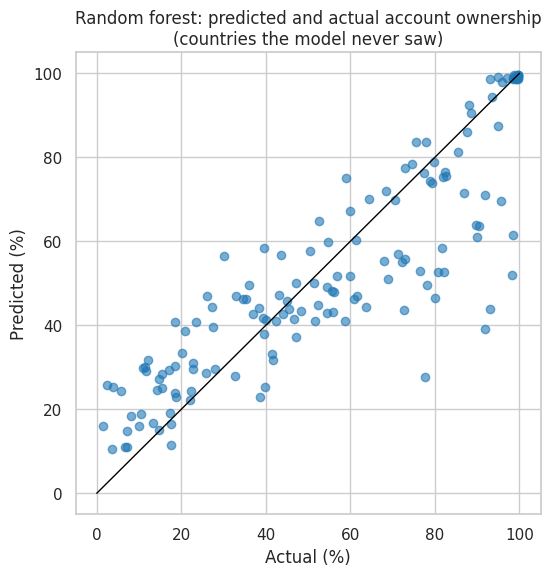

In [20]:
forest = models['Random forest']
test_pred = forest.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_pred, alpha=0.6, color='#1f77b4')
ax.plot([0, 100], [0, 100], color='black', linewidth=1)
ax.set_title('Random forest: predicted and actual account ownership\n'
             '(countries the model never saw)')
ax.set_xlabel('Actual (%)')
ax.set_ylabel('Predicted (%)')
plt.show()

urban_population       -0.07
unemployment           -0.05
labor_participation    -0.00
inflation               0.01
electricity_access      0.16
region                  0.22
mobile_subscriptions    0.24
secondary_enrollment    0.25
bank_branches           0.54
year                    1.34
atms                    1.83
population_65_plus      2.78
internet_users          3.46
log_gdp_per_capita      8.01
dtype: float64


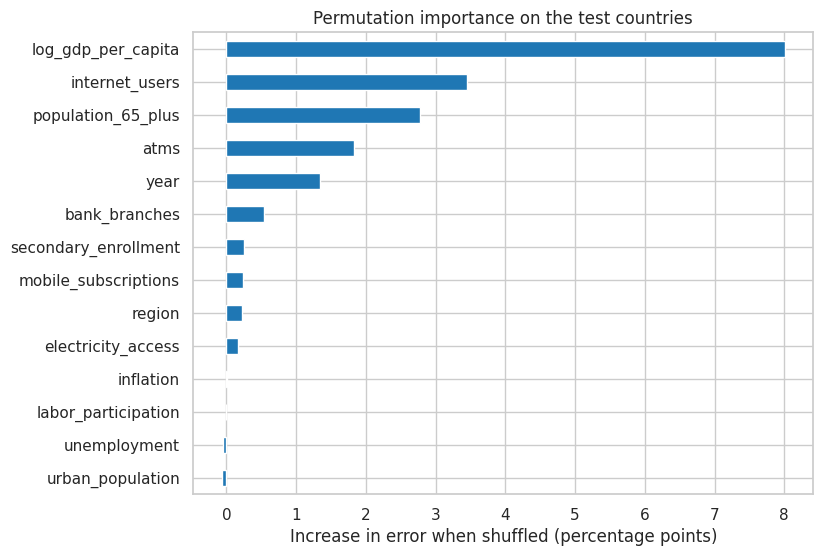

In [21]:
importance = permutation_importance(
    forest, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
    scoring='neg_mean_absolute_error')
importance_table = pd.Series(
    importance.importances_mean, index=FEATURES).sort_values()
print(importance_table.round(2))

ax = importance_table.plot(kind='barh', figsize=(8, 6), color='#1f77b4')
ax.set_title('Permutation importance on the test countries')
ax.set_xlabel('Increase in error when shuffled (percentage points)')
plt.show()

**Answer.** Both models predict account ownership in countries they have never seen to within about 11 percentage points on average.

| Model | R squared | MAE | RMSE |
|---|---|---|---|
| Baseline (training average) | -0.04 | 27.4 | 31.5 |
| Linear regression | 0.78 | 11.1 | 14.6 |
| Random forest | 0.76 | 10.8 | 15.1 |

* **R squared** of about 0.77 means the models explain roughly three quarters of the variation in the test data (148 rows from 33 countries). The baseline's R squared is slightly below zero because the training average differs a little from the test average.
* **MAE** says a typical prediction is off by about 11 points, against 27 points for the baseline. That is good enough to tell a low ownership country from a high one, but not to rank two similar countries.
* **RMSE** is larger than MAE (about 15 against 11), because RMSE gives large errors more weight. Some predictions are therefore well off, as the predicted against actual chart above also shows.
* Five-fold cross-validation by country gives a mean R squared of 0.74 for both models, with folds between 0.63 and 0.88. This supports broadly similar performance across different splits, although the score varies with the countries that are held out.

The two models perform about the same, so the simpler linear regression is a reasonable choice when the result has to be explained.

**What the model relies on.** Shuffling GDP per capita raises the random forest's error by 8.0 percentage points, far more than any other feature. Internet use (3.5), the share of people aged 65 and above (2.8), ATMs (1.8) and the survey year (1.3) come next. Every other feature, including region, changes the error by about half a point or less.

*Limits.* A low score for electricity or schooling does not mean they are unrelated to account ownership (Question 2 shows they are related). It means that shuffling them one at a time changes this model's test error very little, and correlation between features can hide a feature's importance.

### Question 4. Which countries have many more, or many fewer, account owners than their income predicts?

A straight line is fitted between account ownership and the logarithm of GDP per capita for the latest full survey year, 2024. The gap between a country's actual value and the line shows how far it is above or below what income alone would suggest.

In [22]:
latest = df[df['year'] == 2024].dropna(subset=['log_gdp_per_capita']).copy()
income_model = LinearRegression().fit(
    latest[['log_gdp_per_capita']], latest[TARGET])
latest['expected'] = income_model.predict(latest[['log_gdp_per_capita']])
latest['gap'] = latest[TARGET] - latest['expected']
columns = ['country', 'income_group', 'gdp_per_capita', TARGET, 'expected',
           'gap']
print('Countries in 2024:', len(latest))
print('\nFurthest above the income line')
print(latest.nlargest(8, 'gap')[columns].round(1).to_string(index=False))
print('\nFurthest below the income line')
print(latest.nsmallest(8, 'gap')[columns].round(1).to_string(index=False))

Countries in 2024: 139

Furthest above the income line
           country        income_group  gdp_per_capita  account_ownership  expected  gap
             Kenya Lower middle income          2133.5               90.1      53.6 36.5
             India Lower middle income          2592.0               89.0      56.1 32.9
          Mongolia Upper middle income          6750.6               98.3      68.0 30.3
            Uganda          Low income          1077.9               72.8      45.1 27.7
            Zambia Lower middle income          1187.1               72.7      46.3 26.4
Iran, Islamic Rep. Upper middle income          5190.2               91.1      64.7 26.3
             Ghana Lower middle income          2419.3               81.2      55.2 26.0
           Senegal Lower middle income          1738.7               76.5      51.1 25.4

Furthest below the income line
   country        income_group  gdp_per_capita  account_ownership  expected   gap
   Lebanon Lower middle income

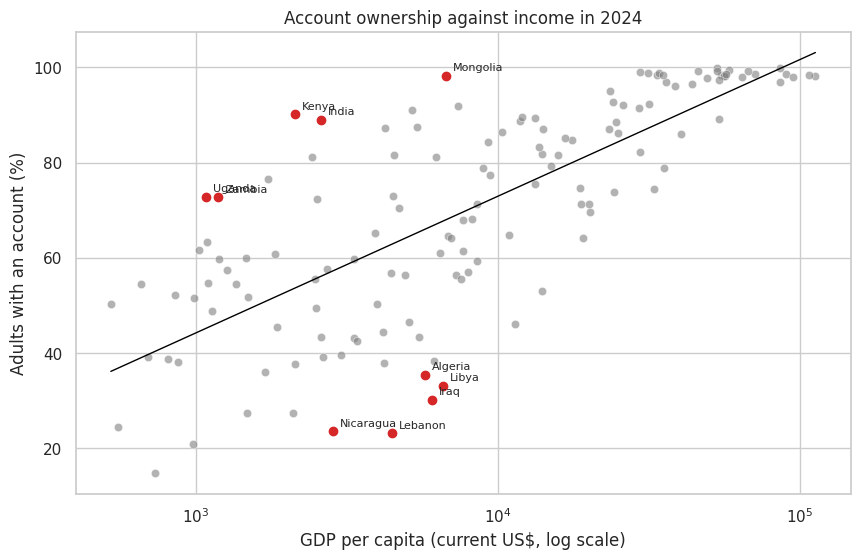

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=latest, x='gdp_per_capita', y=TARGET, color='grey',
                alpha=0.6, ax=ax)
line_x = np.linspace(latest['log_gdp_per_capita'].min(),
                     latest['log_gdp_per_capita'].max(), 50)
line_y = income_model.predict(pd.DataFrame({'log_gdp_per_capita': line_x}))
ax.plot(10 ** line_x, line_y, color='black', linewidth=1)
highlight = pd.concat([latest.nlargest(5, 'gap'), latest.nsmallest(5, 'gap')])
ax.scatter(highlight['gdp_per_capita'], highlight[TARGET], color='#d62728')
for _, row in highlight.iterrows():
    ax.annotate(row['country'], (row['gdp_per_capita'], row[TARGET]),
                textcoords='offset points', xytext=(5, 4), fontsize=8)
ax.set_xscale('log')
ax.set_title('Account ownership against income in 2024')
ax.set_xlabel('GDP per capita (current US$, log scale)')
ax.set_ylabel('Adults with an account (%)')
plt.show()

**Answer.** Income is a strong guide, but some countries are 25 to 40 percentage points away from what it suggests.

*Well above the income line in 2024.* Kenya has 90.1% account ownership where its income suggests 53.6%, a gap of 36.5 points. India (89.0% against 56.1%), Mongolia (98.3% against 68.0%), Uganda (72.8% against 45.1%), Zambia, Iran, Ghana and Senegal are also 25 points or more above the line. Five of these eight are in Sub-Saharan Africa.

*Well below the income line.* Lebanon has 23.0% where its income suggests 62.9%, a gap of 39.8 points. Iraq (30.2%), Libya (33.1%), Nicaragua (23.5%), Algeria (35.3%) and Guatemala (38.3%) are each about 29 to 37 points below the line.

This is the most useful insight for a decision maker: a low or middle income does not fix a country's level of financial inclusion. Kenya has higher account ownership than Iraq, Libya and Guatemala, which each have roughly three times its GDP per capita.

*Limits.* The data cannot say why these countries differ. Mobile money services and government account programs are widely reported explanations for the countries above the line, and banking crises or conflict for some below it, but none of these is measured here.

### Question 5. What does the model predict if internet use rises in a typical lower middle income country?

The starting point is a made-up country whose features equal the 2024 median of lower middle income countries in Sub-Saharan Africa. Internet use is then raised in steps while everything else is held fixed, and both models predict account ownership.

In [24]:
def build_scenario(data, income_group, region, year):
    """Return a one row profile holding the medians of a group of countries.

    Args:
        data (pandas.DataFrame): The cleaned analysis table.
        income_group (str): World Bank income group to take medians from.
        region (str): World Bank region to take medians from.
        year (int): Survey year to take medians from.

    Returns:
        pandas.DataFrame: One row with every model feature.
    """
    group = data[(data['income_group'] == income_group)
                 & (data['region'] == region) & (data['year'] == year)]
    profile = group[NUMERIC_FEATURES].median().to_frame().T
    profile['region'] = region
    print(f'Profile built from {len(group)} countries.')
    return profile[FEATURES]


profile = build_scenario(df, 'Lower middle income', 'Sub-Saharan Africa', 2024)
profile.round(1).T

Profile built from 18 countries.


,0
log_gdp_per_capita,3.3
internet_users,41.5
mobile_subscriptions,108.5
urban_population,47.9
bank_branches,4.4
atms,7.0
secondary_enrollment,70.5
labor_participation,60.5
population_65_plus,3.3
unemployment,4.5


In [25]:
steps = [float(profile['internet_users'].iloc[0]), 50.0, 60.0, 70.0, 80.0]
rows = []
for internet in steps:
    scenario = profile.copy()
    scenario['internet_users'] = internet
    row = {'internet_users': round(internet, 1)}
    for name, model in models.items():
        row[name] = round(float(model.predict(scenario)[0]), 1)
    rows.append(row)
scenario_table = pd.DataFrame(rows).set_index('internet_users')
scenario_table

,Linear regression,Random forest
internet_users,,
41.5,49.8,50.8
50.0,52.0,49.6
60.0,54.5,49.6
70.0,57.0,53.1
80.0,59.5,53.1


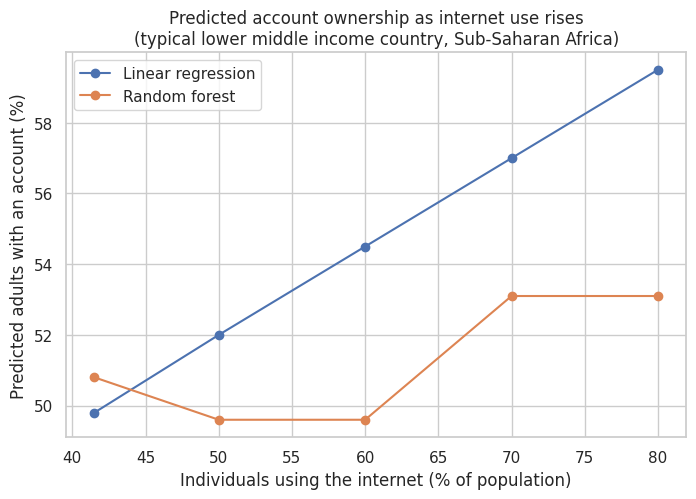

In [26]:
ax = scenario_table.plot(marker='o', figsize=(8, 5))
ax.set_title('Predicted account ownership as internet use rises\n'
             '(typical lower middle income country, Sub-Saharan Africa)')
ax.set_xlabel('Individuals using the internet (% of population)')
ax.set_ylabel('Predicted adults with an account (%)')
plt.show()

**Answer.** The starting profile is the median of the 18 lower middle income countries in Sub-Saharan Africa in 2024, with 41.5% of people using the internet. For that profile the linear regression predicts 49.8% account ownership and the random forest predicts 50.8%.

When internet use is raised to 80% and nothing else changes, the linear regression predicts 59.5% (about 10 points more) and the random forest predicts 53.1% (about 2 points more).

The two models disagree on the size of the change, and that is the honest result. The linear model adds the same amount for every extra point of internet use. The random forest is not smooth: its prediction first falls from 50.8% to 49.6% and then rises to 53.1%. The analysis does not establish why the two respond differently. Both predict higher ownership at 80% than at the starting value, and for this profile the largest increase is 9.7 points for the linear regression and 2.3 points for the random forest.

*Limits.* This is a prediction from patterns across countries, not a forecast of what a policy would do. In real countries internet use rises together with income, schooling and other things that the scenario holds fixed.

## 5. Evaluation and conclusions

**Summary of findings**

1. The median country went from 37.0% of adults with an account in 2011 to 72.8% in 2024. Sub-Saharan Africa and South Asia gained the most. The median for the Middle East, North Africa, Afghanistan and Pakistan region was 46.9% in 2014 and 44.4% in 2024, although the set of countries surveyed changed.
2. GDP per capita (0.81) and internet use (0.80) have the strongest relationship with account ownership. Mobile subscriptions and bank branches are only moderately related.
3. A model using twelve published indicators, the survey year and region predicts account ownership in unseen countries with an R squared of about 0.77 and a typical error of 11 percentage points, against 27 for a baseline. A linear regression does as well as a random forest.
4. Income does not settle the outcome. Kenya, India and Mongolia are more than 30 points above what their income suggests. Lebanon, Iraq and Libya are more than 30 points below.
5. Raising internet use from 41.5% to 80% in a typical lower middle income African country moves the prediction by 2 to 10 points, depending on the model.

**Limitations**

* All results are associations between country level figures. None of them shows cause and effect.
* The Findex survey covers a different set of countries each round, and the data hold at most six observations per country.
* Secondary enrollment is missing for about a quarter of the rows and is filled with the training median, which weakens that feature.
* Things that are likely to matter, such as mobile money services, identity systems and trust in banks, are not in the data.
* Within each survey year the median gives every surveyed country the same weight. The correlations, the models and the error measures use country and year rows, so countries surveyed in more years count for more. Nothing is weighted by population, so the figures do not describe the typical person.

## 6. Deployment

The findings are shared in a blog post for a general audience and in the README of the GitHub repository that holds this notebook.

**Acknowledgements.** Data: World Bank Databank and the Global Findex Database, accessed through the World Bank API. Tools: pandas, NumPy, scikit-learn, Matplotlib and seaborn.